In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
plt.rcParams["font.family"] = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

In [2]:
from sklearn.datasets import load_wine


wine  = load_wine(as_frame=True)

df = wine.frame
df['kind'] = df['target'].map(dict(enumerate(wine.target_names)))
df.shape

(178, 15)

In [4]:
df[wine.feature_names[:4] + ['kind']].head(3)

,alcohol,malic_acid,ash,alcalinity_of_ash,kind
0,14.23,1.71,2.43,15.6,class_0
1,13.20,1.78,2.14,11.2,class_0
2,13.16,2.36,2.67,18.6,class_0


In [6]:
df['kind'].value_counts()

kind
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64

In [7]:
from sklearn.model_selection import train_test_split


X = df[wine.feature_names]
y = df['kind']
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=0)
print("training :", len(X_train), " test :", len(X_test))

training : 142  test : 36


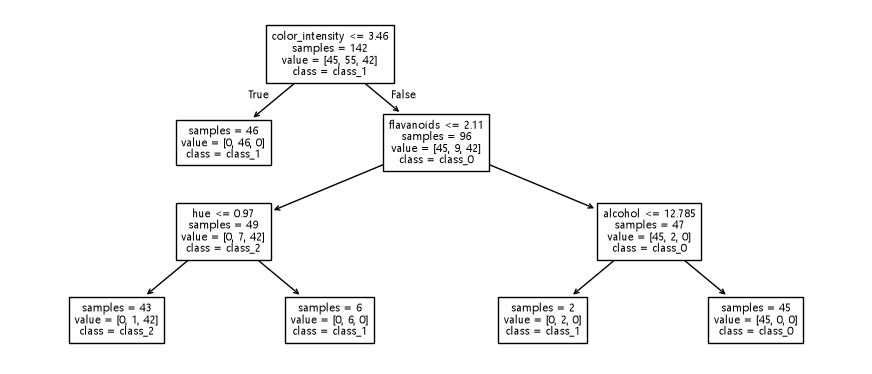

In [8]:
from sklearn.tree import DecisionTreeClassifier


model = DecisionTreeClassifier(max_depth=3,random_state=0)
model.fit(X_train, y_train)

from sklearn.tree import plot_tree

plt.figure(figsize=(11, 4.6))
plot_tree(model, feature_names=wine.feature_names,
class_names=wine.target_names,
impurity=False, fontsize=8)
plt.show()

In [9]:
new = X_test.iloc[[0]] # 줄 하나를 DataFrame 으로 (iloc[0] 이 아님)
print("predict :", model.predict(new)[0], " 실제 :", y_test.iloc[0])
print("proba :", model.predict_proba(new).round(2))

predict : class_0  실제 : class_0
proba : [[1. 0. 0.]]


In [10]:
print("training accuracy :", round(model.score(X_train, y_train), 3))
print("test accuracy :", round(model.score(X_test, y_test), 3))

training accuracy : 0.993
test accuracy : 0.972


In [11]:
from sklearn.metrics import confusion_matrix
pred = model.predict(X_test)
pd.DataFrame(confusion_matrix(y_test, pred),
index=["true_" + n for n in wine.target_names],
columns=["pred_" + n for n in wine.target_names])

,pred_class_0,pred_class_1,pred_class_2
true_class_0,14,0,0
true_class_1,1,15,0
true_class_2,0,0,6


In [12]:
import joblib
joblib.dump(model, "wine_model.pkl")

['wine_model.pkl']

In [13]:
# ⑦ app.py 의 example 값으로 쓸 한 줄
new.round(2).iloc[0]

alcohol                           13.74
malic_acid                         1.67
ash                                2.25
alcalinity_of_ash                 16.40
magnesium                        118.00
total_phenols                      2.60
flavanoids                         2.90
nonflavanoid_phenols               0.21
proanthocyanins                    1.62
color_intensity                    5.85
hue                                0.92
od280/od315_of_diluted_wines       3.20
proline                         1060.00
Name: 54, dtype: float64